# CVE2Patch — Raccolta e ranking delle CVE

Raccolta delle vulnerabilità Linux e delle informazioni pubbliche utili alla successiva generazione e valutazione di regole di detection host-level (Falco, Sigma ed Elastic). Le CVE del kernel vengono trattate separatamente.

### Riferimenti bibliografici

| Fonte | Collegamento con il lavoro |
|---|---|
| [CVEfixes — Bhandari et al., 2021](https://doi.org/10.1145/3475960.3475985) | Acquisizione automatica dei dati NVD e associazione di informazioni esterne tramite CVE ID. |
| [The Anatomy of a Vulnerability Database, 2023](https://doi.org/10.1016/j.jss.2023.111679) | Integrazione di informazioni provenienti da più database. |
| [Jacobs et al., 2020](https://doi.org/10.1093/cybsec/tyaa015) | Differenze di copertura tra fonti di exploit; non si utilizza il modello di previsione del rischio. |
| [Mu et al., 2018](https://www.usenix.org/conference/usenixsecurity18/presentation/mu) | Disponibilità delle informazioni necessarie a riprodurre una vulnerabilità. |
| [CVE-GENIE — Ullah et al., 2025; v2 2026](https://arxiv.org/abs/2509.01835v2) | Raccolta del contesto utile alla riproduzione delle vulnerabilità. |

La selezione riguarda le CVE pubblicate dal 2019, con piattaforma Linux e vettore di attacco Network o Local. Le fonti vengono incrociate tramite CVE ID. Il punteggio misura la disponibilità del contesto documentale, non il rischio o l'efficacia della rilevazione. I pesi sono empirici; i riferimenti bibliografici motivano l'approccio, non i valori numerici.

Eseguire il notebook dalla cartella di lavoro originale. I dataset in `CVE2Patch/data/raw/` vengono riutilizzati se presenti, altrimenti scaricati; i risultati vengono rigenerati. I feed NVD annuali sono suddivisi per anno del CVE ID: possono quindi mancare identificativi precedenti al 2019 pubblicati successivamente. Non vengono scaricati o eseguiti exploit.

**Revisione 4.3:** parsing delle date nei metadati YAML/TOML delle regole gestito in modo esplicito; il criterio di scoring resta invariato.


**Versione 4.4 — benchmark semplice:** esclusione di ambienti Vulhub con più CVE, preferenza per ambienti autonomi, matching conservativo delle regole Sigma/Elastic, senza modificare i pesi. Gli ID con soli ambienti multi-CVE sono rimossi dal pool sperimentale; il log delle esclusioni viene conservato.


## 1. Librerie e funzioni comuni

Import delle dipendenze (Python 3.11+, requests, pandas e PyYAML) e definizione delle funzioni riutilizzate per download, estrazione dei CVE ID, salvataggio e conteggi.


In [1]:
import requests
import pandas as pd
import json
import re
import tomllib
import yaml
import hashlib
import gzip
import zipfile
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from urllib.parse import urlparse, unquote
from IPython.display import display


# Espressione regolare condivisa per i CVE ID.
CVE_PATTERN = re.compile(r"CVE-\d{4}-\d{4,}", re.I)


def cached_download(url, path, timeout=120, validate=None):
    """Scarica il file solo se manca; salva in cache dopo il download."""
    if path.exists():
        if validate is not None and not validate(path):
            raise ValueError(f"File non valido: {path}. Rimuoverlo e rieseguire.")
        return path
    tmp = path.with_name(path.name + ".part")
    try:
        print(f"Download {path.name}...")
        with requests.get(url, stream=True, timeout=timeout) as response:
            response.raise_for_status()
            with tmp.open("wb") as f:
                for chunk in response.iter_content(1024 * 1024):
                    f.write(chunk)
        if validate is not None and not validate(tmp):
            raise ValueError(f"Formato non valido: {url}")
        tmp.replace(path)
    finally:
        tmp.unlink(missing_ok=True)
    return path


def cve_ids(text):
    return sorted({m.upper() for m in CVE_PATTERN.findall(str(text))})


def records_for_ids(ids, fields):
    return ({"cve_id": cve_id, **fields} for cve_id in ids)


def save_table(records, filename, columns=None, deduplicate=True):
    frame = pd.DataFrame(records, columns=columns)
    if deduplicate:
        frame = frame.drop_duplicates()
    frame.to_csv(PROCESSED_DIR / filename, index=False)
    return frame


def report_matches(frame):
    ids = set(frame["cve_id"])
    print(f"Corrispondenze con candidate: {df_candidates['cve_id'].isin(ids).sum()}")
    print(f"Possibili CVE da recuperare: {df_unknown['cve_id'].isin(ids).sum()}")

print("Librerie e funzioni comuni disponibili.")


Librerie e funzioni comuni disponibili.


## 2. Configurazione

Parametri di ricerca: periodo, vettori di attacco, pesi e soglia minima. La somma massima dei contributi deve essere 100. Il pool include tutte le CVE che raggiungono la soglia, senza un limite numerico.


In [2]:
BASE_DIR = Path.cwd() / "CVE2Patch"
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
OUTPUT_DIR = BASE_DIR / "output"
for directory in [RAW_DIR, PROCESSED_DIR, OUTPUT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

START_DATE = "2019-01-01"
END_DATE = "2026-11-17"  # Ultimo giorno incluso
ATTACK_VECTORS = ["NETWORK", "LOCAL"]
MIN_SCORE = 60

WEIGHTS = {
    "vulhub": 30,
    "msf_min": 30,
    "msf_max": 40,
    "edb_verified": 30,
    "edb_unverified": 25,
    "poc_primary": 20,
    "edb_bonus": 5,
    "poc_bonus": 5,
    "detection_rules": 20,
}
assert datetime.fromisoformat(START_DATE) <= datetime.fromisoformat(END_DATE)
assert ATTACK_VECTORS and set(ATTACK_VECTORS) <= {"NETWORK", "LOCAL"}
assert isinstance(MIN_SCORE, (int, float)) and 0 <= MIN_SCORE <= 100
assert all(isinstance(w, (int, float)) and 0 <= w <= 100 for w in WEIGHTS.values())
assert WEIGHTS["msf_max"] >= WEIGHTS["msf_min"] >= WEIGHTS["edb_verified"] >= WEIGHTS["edb_unverified"] >= WEIGHTS["poc_primary"]
assert WEIGHTS["edb_bonus"] <= WEIGHTS["edb_unverified"] and WEIGHTS["poc_bonus"] <= WEIGHTS["poc_primary"]
MAX_EXPLOIT = WEIGHTS["msf_max"] + WEIGHTS["edb_bonus"] + WEIGHTS["poc_bonus"]
MAX_SCORE = MAX_EXPLOIT + WEIGHTS["vulhub"] + WEIGHTS["detection_rules"]
assert abs(MAX_SCORE - 100) < 1e-8, "Ribilanciare i pesi: il massimo deve essere 100."
print(f"Periodo: {START_DATE} - {END_DATE} | Soglia: {MIN_SCORE}/100")
print(f"Directory: {BASE_DIR}")


Periodo: 2019-01-01 - 2026-11-17 | Soglia: 60/100
Directory: d:\leopo\Desktop\Leonardo\Uni\Tesi\Work\CVE\CVE2Patch


## 3. NVD — Acquisizione dei feed

Download dei feed annuali NVD in formato JSON compresso, solo se non sono già presenti in locale.


In [3]:
NVD_DIR = RAW_DIR / "nvd_feeds"
NVD_DIR.mkdir(parents=True, exist_ok=True)
NVD_BASE_URL = "https://nvd.nist.gov/feeds/json/cve/2.0"
NVD_FILES = []
for year in range(int(START_DATE[:4]), int(END_DATE[:4]) + 1):
    filename = f"nvdcve-2.0-{year}.json.gz"
    path = NVD_DIR / filename
    if path.exists():
        print(f"Dataset {year} già disponibile.")
    NVD_FILES.append(cached_download(f"{NVD_BASE_URL}/{filename}", path))
print(f"\nDataset annuali disponibili: {len(NVD_FILES)}")


Dataset 2019 già disponibile.
Dataset 2020 già disponibile.
Dataset 2021 già disponibile.
Dataset 2022 già disponibile.
Dataset 2023 già disponibile.
Dataset 2024 già disponibile.
Dataset 2025 già disponibile.
Dataset 2026 già disponibile.

Dataset annuali disponibili: 8


## 4. NVD — Estrazione e filtraggio

Si escludono le CVE rigettate o fuori periodo. La piattaforma viene ricavata dai CPE, distinguendo il software vulnerabile dai requisiti ambientali; una menzione di Linux nella descrizione non basta per includere una CVE. Il kernel viene identificato a parte e conservato indipendentemente dall'Attack Vector. Per le altre CVE si mantengono Local e Network.

Le piattaforme incerte e non Linux restano disponibili per i controlli successivi. La classificazione delle configurazioni CPE complesse e del kernel è euristica. I tag NVD vengono conservati come metadati, senza contribuire al punteggio.


In [4]:
def extract_cvss(cve):
    for version in ["cvssMetricV40", "cvssMetricV31", "cvssMetricV30", "cvssMetricV2"]:
        entries = cve.get("metrics", {}).get(version, [])
        if entries:
            metric = next((m for m in entries if m.get("type") == "Primary"), entries[0])
            data = metric.get("cvssData", {})
            return data.get("baseScore"), data.get("attackVector", data.get("accessVector")), data.get("version")
    return None, None, None

LINUX_PRODUCTS = {"linux_kernel", "linux", "ubuntu_linux", "ubuntu", "debian_linux", "debian",
                  "fedora", "centos", "rocky_linux", "almalinux", "amazon_linux", "amazon_linux_2",
                  "amazon_linux_2023", "arch_linux", "opensuse", "leap", "tumbleweed", "oracle_linux",
                  "raspberry_pi_os", "kali_linux", "red_hat_enterprise_linux"}
NONLINUX = re.compile(r"^(windows(?:_|$)|macos(?:_|$)|mac_os(?:_|$)|os_x(?:_|$)|ios(?:_|$)|ipados(?:_|$)|android(?:_|$)|freebsd(?:_|$)|openbsd(?:_|$)|netbsd(?:_|$)|solaris(?:_|$)|aix(?:_|$))")
LINUX_TEXT = re.compile(r"\b(?:linux|ubuntu|debian|fedora|centos|red hat|suse|almalinux|rocky linux)\b", re.I)
KERNEL_TEXT = re.compile(r"(?:^\s*(?:in the |the )?linux kernel\b|\b(?:flaw|vulnerability|bug|issue|race condition|use-after-free)\b[^.]{0,65}\b(?:in|within) (?:the )?linux kernel\b)", re.I)


def parse_cpe(match):
    criteria = match.get("criteria", "")
    parts = re.split(r"(?<!\\):", criteria.lower())
    if len(parts) != 13 or parts[:2] != ["cpe", "2.3"]:
        return None
    part, vendor, product, target_sw = parts[2], parts[3], parts[4], parts[10]
    linux = (part == "o" and (product in LINUX_PRODUCTS or product.startswith(("enterprise_linux", "linux_enterprise", "ubuntu_linux", "debian_linux")))) or target_sw == "linux"
    other = (part == "o" and bool(NONLINUX.match(product))) or bool(NONLINUX.match(target_sw))
    return {"criteria": criteria, "vulnerable": match.get("vulnerable") is True,
            "linux": linux, "other": other and not linux, "part": part,
            "kernel": part == "o" and vendor == "linux" and product == "linux_kernel"}


def walk_cpe(obj):
    # I rami negati non vengono considerati; il parsing CPE è euristico.
    if not isinstance(obj, dict) or obj.get("negate", False):
        return [], False
    terms = [p for m in obj.get("cpeMatch", []) if (p := parse_cpe(m)) is not None]
    context = False
    for child in obj.get("nodes", []) + obj.get("children", []):
        child_terms, child_context = walk_cpe(child)
        terms.extend(child_terms)
        context |= child_context
    # Linux non vulnerabile vale come requisito ambientale solo in un ramo AND con software vulnerabile.
    if str(obj.get("operator", "OR")).upper() == "AND":
        context |= (any(t["linux"] and not t["vulnerable"] for t in terms)
                    and any(t["vulnerable"] and t["part"] == "a" and not t["other"] for t in terms))
    return terms, context


def platform_evidence(cve, description):
    terms, linux_context = [], False
    for configuration in cve.get("configurations", []):
        group, context = walk_cpe(configuration)
        terms.extend(group)
        linux_context |= context
    affected = [t for t in terms if t["vulnerable"]]
    linux_direct = any(t["linux"] for t in affected)
    other_only = bool(affected) and all(t["other"] for t in affected) and not linux_context
    kernel = (any(t["kernel"] for t in affected)
              or cve.get("sourceIdentifier", "").lower() == "cve@kernel.org"
              or bool(KERNEL_TEXT.search(description)))
    linux_text = bool(LINUX_TEXT.search(description))
    if kernel:
        status = "kernel"
    elif linux_direct:
        status = "linux_direct"
    elif linux_context:
        status = "linux_context"
    elif other_only:
        status = "nonlinux_cpe"
    else:
        status = "unknown"
    return {"platform_nvd": status, "linux_direct": linux_direct, "linux_context": linux_context,
            "linux_text": linux_text, "kernel": kernel,
            "cpe": json.dumps(sorted({t["criteria"] for t in terms})),
            "vulnerable_cpe": json.dumps(sorted({t["criteria"] for t in affected}))}


records = []
for file_path in NVD_FILES:
    with gzip.open(file_path, "rt", encoding="utf-8") as f:
        data = json.load(f)
    for item in data["vulnerabilities"]:
        cve = item["cve"]
        description = next((d["value"] for d in cve.get("descriptions", []) if d.get("lang") == "en"), "")
        cvss, attack_vector, cvss_version = extract_cvss(cve)
        cwes = sorted({d["value"] for w in cve.get("weaknesses", []) for d in w.get("description", [])})
        references = sorted({r["url"] for r in cve.get("references", []) if r.get("url")})
        reference_details = [{"url": r["url"], "source": r.get("source"), "tags": r.get("tags", [])}
                             for r in cve.get("references", []) if r.get("url")]
        records.append({"cve_id": cve["id"], "published": cve.get("published"),
                        "description": description, "status": cve.get("vulnStatus"),
                        "cvss": cvss, "cvss_version": cvss_version, "attack_vector": attack_vector,
                        "cwe": json.dumps(cwes), "references": json.dumps(references),
                        "reference_details": json.dumps(reference_details, ensure_ascii=False),
                        **platform_evidence(cve, description)})
    print(f"Letto {file_path.name}")
    del data

df_all = pd.DataFrame(records).drop_duplicates("cve_id").reset_index(drop=True)
del records
in_period = df_all["published"].fillna("").str[:10].between(START_DATE, END_DATE)
df_valid = df_all[in_period & df_all["status"].ne("Rejected")].copy()
# Separazione per piattaforma prima del filtro AV.
df_linux_pre_av = df_valid[df_valid["platform_nvd"].isin(["linux_direct", "linux_context"])].copy()
df_unknown_pre_av = df_valid[df_valid["platform_nvd"].eq("unknown")].copy()
df_nonlinux_pre_av = df_valid[df_valid["platform_nvd"].eq("nonlinux_cpe")].copy()
df_kernel = df_valid[df_valid["kernel"]].copy()
assert len(df_valid) == sum(map(len, [df_linux_pre_av, df_unknown_pre_av, df_nonlinux_pre_av, df_kernel]))

def allowed_av(frame):
    return frame[frame["attack_vector"].isin(ATTACK_VECTORS)].copy()

df_candidates = allowed_av(df_linux_pre_av)
df_unknown = allowed_av(df_unknown_pre_av)
df_nonlinux = allowed_av(df_nonlinux_pre_av)
df_non_kernel = df_valid[~df_valid["kernel"]].copy()
df_av = pd.concat([df_candidates, df_unknown, df_nonlinux], ignore_index=True)
df_av_excluded = df_non_kernel[~df_non_kernel["attack_vector"].isin(ATTACK_VECTORS)].copy()
assert len(df_av) + len(df_av_excluded) + len(df_kernel) == len(df_valid)

for name, frame in {"all_cves": df_all, "kernel_cves": df_kernel,
                    "candidates": df_candidates, "platform_unknown": df_unknown,
                    "platform_nonlinux": df_nonlinux, "attack_vector_excluded": df_av_excluded}.items():
    frame.to_csv(PROCESSED_DIR / f"{name}.csv", index=False)

print(f"Record NVD unici: {len(df_all)}")
print(f"Non rigettate nel periodo: {len(df_valid)}")
print("Classificazione piattaforma prima dell'AV:")
print(df_valid["platform_nvd"].value_counts())
print(f"Kernel separato (tutti gli AV): {len(df_kernel)}")
print(f"Linux NVD con AV ammesso: {len(df_candidates)}")
print(f"Piattaforma incerta con AV ammesso: {len(df_unknown)}")
print(f"Non Linux con AV ammesso: {len(df_nonlinux)}")
print(f"Non kernel con AV escluso: {len(df_av_excluded)}")


Letto nvdcve-2.0-2019.json.gz
Letto nvdcve-2.0-2020.json.gz
Letto nvdcve-2.0-2021.json.gz
Letto nvdcve-2.0-2022.json.gz
Letto nvdcve-2.0-2023.json.gz
Letto nvdcve-2.0-2024.json.gz
Letto nvdcve-2.0-2025.json.gz
Letto nvdcve-2.0-2026.json.gz
Record NVD unici: 299490
Non rigettate nel periodo: 289125
Classificazione piattaforma prima dell'AV:
platform_nvd
unknown          240351
kernel            19482
nonlinux_cpe      18266
linux_direct       8026
linux_context      3000
Name: count, dtype: int64
Kernel separato (tutti gli AV): 19482
Linux NVD con AV ammesso: 10835
Piattaforma incerta con AV ammesso: 231922
Non Linux con AV ammesso: 17348
Non kernel con AV escluso: 9538


## 5. Vulhub — Ambienti vulnerabili

L'indice Vulhub permette di associare le CVE agli ambienti disponibili. **Per semplificare il benchmark, escludiamo ambienti che l'indice associa a più CVE** e conserviamo soltanto gli ambienti mono-CVE. La presenza nell'indice non implica che l'ambiente sia stato testato da noi.


In [5]:
VULHUB_URL = "https://raw.githubusercontent.com/vulhub/vulhub/master/environments.toml"
vulhub_file = cached_download(VULHUB_URL, RAW_DIR / "vulhub_environments.toml", timeout=60)
with vulhub_file.open("rb") as f:
    vulhub_data = tomllib.load(f)

# Benchmark semplice: scartiamo ambienti dichiarati per più CVE.
# Se una CVE ha un ambiente mono-CVE e uno multi-CVE, teniamo solo quello mono-CVE.
vulhub_records = []
vulhub_multicve_records = []
for env in vulhub_data["environment"]:
    ids = sorted({str(c).upper() for c in env.get("cve", [])
                  if re.fullmatch(r"CVE-\d{4}-\d{4,}", str(c), flags=re.I)})
    fields = {
        "vulhub_name": env.get("name"), "vulhub_app": env.get("app"),
        "vulhub_path": env.get("path"), "vulhub_tags": json.dumps(env.get("tags", []), default=str),
        "vulhub_url": "https://github.com/vulhub/vulhub/tree/master/" + (env.get("path") or ""),
    }
    if len(ids) > 1:
        vulhub_multicve_records.extend(records_for_ids(ids, {
            **fields, "associated_cves": json.dumps(ids),
            "reject_reason": "multicve_environment"}))
    elif len(ids) == 1:
        vulhub_records.extend(records_for_ids(ids, fields))

vulhub_columns = ["cve_id", "vulhub_name", "vulhub_app", "vulhub_path", "vulhub_tags", "vulhub_url"]
df_vulhub = save_table(vulhub_records, "vulhub.csv", columns=vulhub_columns, deduplicate=False)
df_vulhub_multicve = save_table(vulhub_multicve_records, "vulhub_multicve_excluded.csv",
    columns=vulhub_columns + ["associated_cves", "reject_reason"], deduplicate=False)
# Si escludono dal benchmark le CVE presenti soltanto in ambienti multi-CVE.
# Quelle che possiedono anche un ambiente autonomo sono conservate.
vulhub_multicve_only_ids = set(df_vulhub_multicve["cve_id"]) - set(df_vulhub["cve_id"])
print(f"Ambienti Vulhub: {len(vulhub_data['environment'])} | "
      f"associazioni mono-CVE: {len(df_vulhub)} | "
      f"associazioni multi-CVE escluse: {len(df_vulhub_multicve)}")
print(f"CVE con soli ambienti multi-CVE (da escludere): {len(vulhub_multicve_only_ids)}")
print(f"CVE uniche ammissibili da Vulhub: {df_vulhub['cve_id'].nunique()}")
report_matches(df_vulhub)
display(df_vulhub.head())


Ambienti Vulhub: 334 | associazioni mono-CVE: 266 | associazioni multi-CVE escluse: 12
CVE con soli ambienti multi-CVE (da escludere): 11
CVE uniche ammissibili da Vulhub: 263
Corrispondenze con candidate: 44
Possibili CVE da recuperare: 125


,cve_id,vulhub_name,vulhub_app,vulhub_path,vulhub_tags,vulhub_url
0,CVE-2024-39907,1Panel Control Panel PostAuth SQL Injection,1panel,1panel/CVE-2024-39907,"[""SQL Injection""]",https://github.com/vulhub/vulhub/tree/master/1...
1,CVE-2015-5254,Apache ActiveMQ Deserialization,Apache ActiveMQ,activemq/CVE-2015-5254,"[""Deserialization"", ""RCE"", ""Message Queue""]",https://github.com/vulhub/vulhub/tree/master/a...
2,CVE-2016-3088,Apache ActiveMQ Arbitrary File Write,Apache ActiveMQ,activemq/CVE-2016-3088,"[""File Upload"", ""RCE"", ""Message Queue""]",https://github.com/vulhub/vulhub/tree/master/a...
3,CVE-2022-41678,Apache ActiveMQ Jolokia Authenticated Remote C...,Apache ActiveMQ,activemq/CVE-2022-41678,"[""RCE"", ""Message Queue""]",https://github.com/vulhub/vulhub/tree/master/a...
4,CVE-2023-46604,Apache ActiveMQ OpenWire Protocol Deserializat...,Apache ActiveMQ,activemq/CVE-2023-46604,"[""RCE"", ""Deserialization"", ""Message Queue""]",https://github.com/vulhub/vulhub/tree/master/a...


## 6. Metasploit — Metadati dei moduli

Associazione dei moduli alle CVE, conservando tipo, piattaforma e rank. Per il ranking si considerano solo i moduli exploit compatibili (sezione 10). In presenza di più moduli si usa il rank valido più alto.


In [6]:
MSF_URL = "https://raw.githubusercontent.com/rapid7/metasploit-framework/master/db/modules_metadata_base.json"
msf_file = cached_download(MSF_URL, RAW_DIR / "metasploit_metadata.json")
msf_data = json.loads(msf_file.read_text(encoding="utf-8"))

msf_records = []
for module in msf_data.values():
    references = module.get("references", [])
    fields = {
        "msf_name": module.get("name"), "msf_module": module.get("fullname"),
        "msf_type": module.get("type"), "msf_platform": module.get("platform"),
        "msf_rank": module.get("rank"), "msf_description": module.get("description"),
        "msf_references": json.dumps(references, ensure_ascii=False),
    }
    msf_records.extend(records_for_ids(cve_ids(json.dumps(references)), fields))

df_msf = save_table(msf_records, "metasploit.csv", columns=[
    "cve_id", "msf_name", "msf_module", "msf_type", "msf_platform", "msf_rank", "msf_description", "msf_references"
])
df_msf_exploits = df_msf[df_msf["msf_type"].eq("exploit")].copy()
print(f"Moduli Metasploit: {len(msf_data)}")
print(f"CVE uniche: {df_msf['cve_id'].nunique()}")
print(f"CVE associate a exploit: {df_msf_exploits['cve_id'].nunique()}")
report_matches(df_msf_exploits)
display(df_msf.head())


Moduli Metasploit: 7268
CVE uniche: 3249
CVE associate a exploit: 2604
Corrispondenze con candidate: 66
Possibili CVE da recuperare: 790


,cve_id,msf_name,msf_module,msf_type,msf_platform,msf_rank,msf_description,msf_references
0,CVE-2007-4387,2Wire Cross-Site Request Forgery Password Rese...,auxiliary/admin/2wire/xslt_password_reset,auxiliary,,300,This module will reset the admin password on a...,"[""CVE-2007-4387"", ""OSVDB-37667"", ""BID-36075"", ..."
1,CVE-2014-6041,Android Browser RCE Through Google Play Store XFO,auxiliary/admin/android/google_play_store_uxss...,auxiliary,,300,This module combines two vulnerabilities to ac...,"[""URL-http://web.archive.org/web/2023032103473..."
2,CVE-2005-2611,Veritas Backup Exec Windows Remote File Access,auxiliary/admin/backupexec/dump,auxiliary,,300,This module abuses a logic flaw in the Backup ...,"[""CVE-2005-2611"", ""OSVDB-18695"", ""BID-14551"", ..."
3,CVE-2005-0771,Veritas Backup Exec Server Registry Access,auxiliary/admin/backupexec/registry,auxiliary,,300,This modules exploits a remote registry access...,"[""OSVDB-17627"", ""CVE-2005-0771"", ""URL-https://..."
4,CVE-2004-0795,IBM DB2 db2rcmd.exe Command Execution Vulnerab...,auxiliary/admin/db2/db2rcmd,auxiliary,,300,This module exploits a vulnerability in the Re...,"[""CVE-2004-0795"", ""OSVDB-4180"", ""BID-9821""]"


## 7. Exploit-DB — Metadati degli exploit

Estrazione degli exploit associati alle CVE, della piattaforma e dello stato `verified`. Si conservano anche quelli non verificati. La verifica di Exploit-DB non equivale a una prova di riproducibilità nel nostro ambiente.


In [7]:
EDB_URL = "https://gitlab.com/exploit-database/exploitdb/-/raw/main/files_exploits.csv"
edb_file = cached_download(EDB_URL, RAW_DIR / "exploitdb.csv")
edb_data = pd.read_csv(edb_file).fillna("")

# Colonne da estrarre dal CSV.
EDB_FIELDS = {"edb_id": "id", "edb_description": "description", "edb_type": "type",
              "edb_platform": "platform", "edb_verified": "verified", "edb_date": "date_published",
              "edb_file": "file"}
edb_records = []
for row in edb_data.to_dict("records"):
    fields = {field: row.get(original) for field, original in EDB_FIELDS.items()}
    edb_records.extend(records_for_ids(cve_ids(row.get("codes", "")), fields))

df_edb = save_table(edb_records, "exploitdb.csv", columns=["cve_id", *EDB_FIELDS])
print(f"Exploit indicizzati: {len(edb_data)}")
print(f"CVE uniche: {df_edb['cve_id'].nunique()}")
report_matches(df_edb)
display(df_edb.head())


Exploit indicizzati: 47182
CVE uniche: 25095
Corrispondenze con candidate: 110
Possibili CVE da recuperare: 1871


,cve_id,edb_id,edb_description,edb_type,edb_platform,edb_verified,edb_date,edb_file
0,CVE-2009-3699,16929,AIX Calendar Manager Service Daemon (rpc.cmsd)...,dos,aix,1,2010-11-11,exploits/aix/dos/16929.rb
1,CVE-1999-1015,19046,AppleShare IP Mail Server 5.0.3 - Buffer Overflow,dos,aix,1,1999-10-15,exploits/aix/dos/19046.txt
2,CVE-2003-0087,22249,IBM AIX 4.3.3/5.1/5.2 - 'libIM' Buffer Overflow,dos,aix,1,2003-02-12,exploits/aix/dos/22249.txt
3,CVE-2009-4265,16657,PointDev IDEAL Migration - Buffer Overflow (Me...,dos,aix,1,2010-09-25,exploits/aix/dos/16657.rb
4,CVE-2014-9349,35342,RobotStats 1.0 - HTML Injection,dos,aix,0,2014-11-24,exploits/aix/dos/35342.txt


## 8. GitHub e riferimenti PoC

I riferimenti GitHub di NVD vengono conservati come contesto. Per individuare potenziali PoC si utilizzano gli indici pubblici [nomi-sec/PoC-in-GitHub](https://github.com/nomi-sec/PoC-in-GitHub) (JSON) e [trickest/cve](https://github.com/trickest/cve) (Markdown).

Si leggono solo gli indici locali, senza scaricare il codice dei repository. Un riferimento viene considerato un potenziale PoC se contiene un'indicazione esplicita di exploit o PoC associata alla CVE; non è una verifica del codice. I duplicati evidenti vengono esclusi dal contributo al ranking. Se un indice manca o il formato non è riconosciuto, l'elaborazione si interrompe per evitare risultati parziali.


In [8]:
GITHUB_TYPES = {"advisories": "advisory", "commit": "commit", "issues": "issue", "pull": "pull_request"}
github_records = []
df_search = pd.concat([df_av, df_kernel], ignore_index=True)[["cve_id", "references"]].drop_duplicates("cve_id")
for row in df_search.itertuples(index=False):
    for url in json.loads(row.references):
        try:
            parsed = urlparse(url)
            hostname = parsed.hostname
        except ValueError:
            continue
        parts = parsed.path.strip("/").split("/")
        if hostname not in ["github.com", "www.github.com"] or len(parts) < 2:
            continue
        repository = None if parts[0] == "advisories" else "/".join(parts[:2])
        fallback = "repository" if len(parts) == 2 else "file" if "blob" in parts else "other"
        reference_type = next((kind for segment, kind in GITHUB_TYPES.items() if segment in parts), fallback)
        github_records.append({"cve_id": row.cve_id, "github_repository": repository,
                               "github_url": url, "github_type": reference_type})

df_github = save_table(github_records, "github_references.csv", columns=[
    "cve_id", "github_repository", "github_url", "github_type"
])
print(f"Riferimenti GitHub di NVD: {len(df_github)} (informativi)")

# Download dei soli archivi degli indici.
POC_INDEXES = {
    "nomi-sec": ("https://codeload.github.com/nomi-sec/PoC-in-GitHub/zip/refs/heads/master", "poc_nomi_sec.zip", ".json"),
    "trickest": ("https://codeload.github.com/trickest/cve/zip/refs/heads/main", "poc_trickest.zip", ".md"),
}

def cached_zip(url, path):
    try:
        return cached_download(url, path, timeout=(20, 180), validate=zipfile.is_zipfile)
    except Exception as exc:
        raise RuntimeError(f"Indice PoC non disponibile: {url}. Rieseguire la cella 8; nessun ranking V4 completo è prodotto.") from exc

POC_CUE = re.compile(r"(?<![a-z0-9])(?:poc|proof[-_ ]?of[-_ ]?concept|exploits?)(?![a-z0-9])", re.I)
URL_PATTERN = re.compile(r"https?://[^\s<>\]\)\"']+", re.I)

def normalize_url(url):
    try:
        p = urlparse(str(url).strip().rstrip(".,;"))
        if p.scheme not in {"http", "https"} or not p.hostname:
            return None
        host = p.hostname.lower().removeprefix("www.")
        path = unquote(p.path).rstrip("/")
        if host == "github.com":
            path = path.lower().removesuffix(".git")
        return host + path + ("?" + p.query if p.query else "")
    except ValueError:
        return None

# La sola presenza del CVE ID non identifica un PoC.
# nomi-sec: nome, descrizione e topics; trickest: testo del riferimento.
def explicit_poc(cve_id, text):
    text = unquote(str(text))
    return bool(POC_CUE.search(text) and cve_id in cve_ids(text))

def trickest_links(text):
    # Intestazioni usate nel Markdown di trickest.
    # Estrae i link solo dalle sezioni PoC.
    in_poc = False
    for line in text.splitlines():
        head = re.match(r"^\s*(#{1,6})\s+(.+?)\s*$", line)
        if head:
            level, label = len(head[1]), head[2].strip().casefold()
            if level <= 3:
                in_poc = label in {"poc", "proof of concept", "proof-of-concept"}
            continue
        if in_poc and not line.lstrip().startswith("!["):
            for url in URL_PATTERN.findall(line):
                yield url.rstrip(".,;")

wanted_ids = set(df_candidates["cve_id"]) | set(df_unknown["cve_id"]) | set(df_kernel["cve_id"])
poc_records = []
poc_input_files = []
poc_index_status = {}
for source, (url, filename, extension) in POC_INDEXES.items():
    path = cached_zip(url, RAW_DIR / filename)
    poc_input_files.append(path)
    matched_files = parsed_files = recognized_sections = 0
    with zipfile.ZipFile(path) as archive:
        for member in archive.infolist():
            entry = PurePosixPath(member.filename)
            if entry.suffix != extension or not CVE_PATTERN.fullmatch(entry.stem):
                continue
            cve_id = entry.stem.upper()
            if cve_id not in wanted_ids:
                continue
            matched_files += 1
            raw = archive.read(member).decode("utf-8")
            if source == "nomi-sec":
                items = json.loads(raw)
                if not isinstance(items, list):
                    raise ValueError(f"Formato nomi-sec inatteso in {entry}")
                for item in items:
                    if not isinstance(item, dict):
                        raise ValueError(f"Record nomi-sec inatteso in {entry}")
                    link = item.get("html_url")
                    if not isinstance(link, str):
                        continue
                    text = " ".join(str(item.get(k) or "") for k in ("full_name", "name", "description", "topics"))
                    poc_records.append((cve_id, source, link, explicit_poc(cve_id, text)))
            else:
                if re.search(r"(?im)^#{1,3}\s+POC\s*$", raw):
                    recognized_sections += 1
                for link in trickest_links(raw):
                    poc_records.append((cve_id, source, link, explicit_poc(cve_id, link)))
            parsed_files += 1
    if wanted_ids and not matched_files:
        print(f"ATTENZIONE: {source}, nessun file per gli ID richiesti; verificare la copertura.")
    if source == "trickest" and matched_files and not recognized_sections:
        raise ValueError("Formato Trickest non riconosciuto: controllare le intestazioni POC.")
    poc_index_status[source] = {"url": url, "status": "consulted", "matched_files": matched_files,
                                "parsed_files": parsed_files, "poc_sections": recognized_sections if source == "trickest" else None}
    print(f"{source}: {parsed_files} file di indice letti")

df_poc = pd.DataFrame(poc_records, columns=["cve_id", "poc_index", "poc_url", "explicit_poc_hint"])
df_poc["normalized_url"] = df_poc["poc_url"].map(normalize_url)
df_poc = df_poc.dropna(subset=["normalized_url"]).drop_duplicates(["cve_id", "poc_index", "normalized_url"])
# Conserva i riferimenti; i duplicati vengono gestiti durante l’integrazione.
df_poc.to_csv(PROCESSED_DIR / "poc_index_references.csv", index=False)
print(f"Riferimenti dagli indici: {len(df_poc)}; con indizio specifico PoC: {df_poc['explicit_poc_hint'].sum()}")


Riferimenti GitHub di NVD: 148369 (informativi)
nomi-sec: 8884 file di indice letti
trickest: 117902 file di indice letti
Riferimenti dagli indici: 298511; con indizio specifico PoC: 10073


## 9. Falco, SigmaHQ ed Elastic — Regole pubbliche

Tre repository ufficiali vengono indicizzati e incrociati tramite CVE ID:

- **Falco**: YAML Stable, Incubating, Sandbox; per il punteggio si mantengono soltanto regole `source: syscall`.
- **SigmaHQ**: file YAML delle directory `rules/`, `rules-emerging-threats/` e `rules-threat-hunting/`. Vengono considerate regole con `logsource.product: linux` o Unix/POSIX, oppure senza vincoli espliciti a sistemi non Linux. Si riconosce anche il tag Sigma `cve.YYYY-NNNNN`.
- **Elastic**: file TOML in `rules/` e `rules_building_block/`, limitati a regole chiaramente compatibili con Linux (`OS: Linux`, percorso Linux o vincolo Linux nella query).

**Scoring:** una CVE con almeno una corrispondenza ammissibile su uno qualsiasi dei tre repository guadagna **20 punti complessivi**, **mai cumulativi**. I nomi, gli identificativi, le sorgenti e gli URL delle regole rimangono negli attributi e nei CSV dedicati; un match indica un **riferimento testuale alla CVE**, non una rilevazione dimostrata.

Per evitare chiamate API per migliaia di file, Sigma ed Elastic vengono scaricati ciascuno come singolo archivio ZIP ufficiale e letti *in memoria*, senza estrarre tutto il repository. Gli archivi vengono conservati in `data/raw` e inseriti nel manifest con hash SHA-256. Il download è necessario **solo alla prima esecuzione** (o dopo aver eliminato il file di cache); l'assenza di una fonte non viene interpretata silenziosamente come assenza di regole.
**Politica conservativa v4.4:** Sigma usa tag, titolo o percorso (non il testo completo); Elastic usa nome, tag o descrizione (non query, esclusioni o mere URL), escludendo regole deprecate e associazioni esplicitamente multi-CVE.


In [9]:
# Falco: comportamento esistente, con un solo match per regola/CVE.
# PyYAML converte i campi come `date: 2026-01-01` in oggetti datetime.date.
# `default=str` rende serializzabili i metadati conservando il testo delle CVE.
def rule_as_json(value):
    return json.dumps(value, ensure_ascii=False, default=str)

FALCO_BASE_URL = "https://raw.githubusercontent.com/falcosecurity/rules/main/rules/"
FALCO_FILES = {"stable": "falco_rules.yaml", "incubating": "falco-incubating_rules.yaml",
               "sandbox": "falco-sandbox_rules.yaml"}
falco_records, total_rules = [], 0
for maturity, filename in FALCO_FILES.items():
    path = cached_download(FALCO_BASE_URL + filename, RAW_DIR / filename, timeout=60)
    rules = yaml.safe_load(path.read_text(encoding="utf-8"))
    for rule in rules:
        if not isinstance(rule, dict) or "rule" not in rule:
            continue
        total_rules += 1
        fields = {
            "falco_rule": rule.get("rule"), "falco_description": rule.get("desc"),
            "falco_priority": rule.get("priority"), "falco_maturity": maturity,
            "falco_enabled": rule.get("enabled"), "falco_source": rule.get("source", "syscall"),
            "falco_url": "https://github.com/falcosecurity/rules/blob/main/rules/" + filename,
        }
        falco_records.extend(records_for_ids(cve_ids(rule_as_json(rule)), fields))

df_falco = save_table(falco_records, "falco_rules.csv", columns=[
    "cve_id", "falco_rule", "falco_description", "falco_priority", "falco_maturity",
    "falco_enabled", "falco_source", "falco_url"
])
print(f"Regole Falco analizzate: {total_rules} | Associazioni: {len(df_falco)}")
report_matches(df_falco)

# Sigma utilizza anche i tag del tipo 'cve.2021-44228' (non riconosciuti
# dall'espressione regolare generale utilizzata dalle altre sorgenti).
RULE_CVE_PATTERN = re.compile(r"(?<![A-Za-z0-9])CVE[-._](\d{4})[-._](\d{4,})(?!\d)", re.I)

def rule_cve_ids(text):
    return sorted({f"CVE-{m.group(1)}-{m.group(2)}" for m in RULE_CVE_PATTERN.finditer(str(text))})

RULE_REPOSITORIES = {
    "sigma": {"repo": "SigmaHQ/sigma", "branch": "master", "zip": "sigma_master.zip",
              "paths": ("rules/", "rules-emerging-threats/", "rules-threat-hunting/"),
              "extensions": (".yml", ".yaml")},
    "elastic": {"repo": "elastic/detection-rules", "branch": "main", "zip": "elastic_main.zip",
                "paths": ("rules/", "rules_building_block/"),
                "extensions": (".toml",)},
}

def read_public_rule_archive(kind):
    """Restituisce (relpath, dict), solo per regole con un riferimento testuale CVE.

    Gli errori YAML/TOML non vengono trasformati in assenza di corrispondenze:
    sono contabilizzati e segnalati al termine dell'indicizzazione.
    """
    cfg = RULE_REPOSITORIES[kind]
    url = f"https://github.com/{cfg['repo']}/archive/refs/heads/{cfg['branch']}.zip"
    archive = cached_download(url, RAW_DIR / cfg["zip"], timeout=180, validate=zipfile.is_zipfile)
    results, errors, scanned = [], [], 0
    with zipfile.ZipFile(archive) as z:
        for info in z.infolist():
            if info.is_dir() or info.file_size > 3_000_000:
                continue
            relpath = info.filename.partition("/")[2]
            if not relpath.startswith(cfg["paths"]) or not relpath.lower().endswith(cfg["extensions"]):
                continue
            scanned += 1
            raw = z.read(info).decode("utf-8-sig", errors="replace")
            if not (RULE_CVE_PATTERN.search(raw) or RULE_CVE_PATTERN.search(relpath)):
                continue
            try:
                if kind == "sigma":
                    documents = yaml.safe_load_all(raw)
                else:
                    documents = [tomllib.loads(raw)]
                for doc in documents:
                    if isinstance(doc, dict):
                        results.append((relpath, doc))
            except (yaml.YAMLError, ValueError, TypeError) as exc:
                errors.append(f"{relpath}: {exc}")
    if errors:
        raise ValueError(f"{kind}: {len(errors)} regole contenenti CVE non analizzabili; "
                         f"primo errore: {errors[0]}")
    print(f"{kind.upper()}: {scanned} file analizzati, {len(results)} documenti con possibile riferimento CVE")
    return results, archive


def sigma_linux_scope(rule, path):
    """Evita di premiare regole dichiaratamente di altri sistemi operativi."""
    logsource = rule.get("logsource") or {}
    if not isinstance(logsource, dict):
        return None
    product = str(logsource.get("product") or "").strip().lower()
    if product:
        return "linux" if product in {"linux", "unix", "posix"} else None
    segments = {segment.lower() for segment in path.split("/")}
    if segments & {"windows", "macos", "osx", "android", "ios"}:
        return None
    return "linux" if "linux" in segments else "generic"


def elastic_linux_scope(rule, path):
    tags = rule.get("tags") or []
    if isinstance(tags, str):
        tags = [tags]
    os_tags = {str(t).split(":", 1)[1].strip().lower()
               for t in tags if str(t).lower().startswith("os:")}
    if os_tags:
        return "linux" if "linux" in os_tags else None
    segments = {segment.lower() for segment in path.split("/")}
    query = str(rule.get("query") or "").lower()
    if "linux" in segments or re.search(r"host\.os\.type\s*(?:==|:)\s*['\"]linux['\"]", query):
        return "linux"
    # Il repo contiene molte regole Windows e macOS: non attribuire loro punti
    # senza un'indicazione esplicita di compatibilità Linux.
    return None

def sigma_rule_cve_ids(rule, relpath):
    """Preferenza: tag CVE > titolo > directory > nome file.

    Con più CVE, o conflitto tra campi autorevoli, saltiamo la regola:
    il primo benchmark non valuta catene né abbinamenti incerti.
    Descrizioni, condizioni e riferimenti NON sono usati per assegnare CVE.
    """
    if str(rule.get("status") or "").lower() in {"deprecated", "unsupported"}:
        return []
    title = str(rule.get("title") or "")
    if title.strip().lower().startswith("deprecated"):
        return []
    tags = rule.get("tags") or []
    if isinstance(tags, str):
        tags = [tags]
    tags_ids = rule_cve_ids(" ".join(map(str, tags)))
    title_ids = rule_cve_ids(title)
    path_segments = PurePosixPath(relpath)
    folder_ids = rule_cve_ids(str(path_segments.parent))
    filename_ids = rule_cve_ids(path_segments.name)

    # Non premiamo regole multi-CVE, nemmeno se i tag sono corretti.
    if any(len(ids) > 1 for ids in (tags_ids, title_ids, folder_ids)):
        return []
    if tags_ids:
        if (title_ids and title_ids != tags_ids) or (folder_ids and folder_ids != tags_ids):
            return []
        return tags_ids
    if title_ids:
        if folder_ids and folder_ids != title_ids:
            return []
        return title_ids
    if folder_ids:
        return folder_ids
    return filename_ids if len(filename_ids) == 1 else []


def elastic_rule_cve_ids(rule, relpath):
    """Una CVE esplicita nel nome/tag/descrizione, non in query o eccezioni.

    Le regole deprecate e quelle che citano più CVE vengono escluse per
    privilegiare un benchmark semplice e conservativo.
    """
    title = str(rule.get("name") or "")
    path_parts = {part.lower() for part in PurePosixPath(relpath).parts}
    if (title.strip().lower().startswith("deprecated")
            or rule.get("deprecated") is True
            or "_deprecated" in path_parts or "deprecated" in path_parts):
        return []
    tags = rule.get("tags") or []
    if isinstance(tags, str):
        tags = [tags]
    name_ids = rule_cve_ids(title)
    tag_ids = rule_cve_ids(" ".join(map(str, tags)))
    description_ids = rule_cve_ids(rule.get("description") or "")
    if any(len(ids) > 1 for ids in (name_ids, tag_ids, description_ids)):
        return []
    if name_ids:
        if (tag_ids and tag_ids != name_ids) or (description_ids and description_ids != name_ids):
            return []
        return name_ids
    if tag_ids:
        if description_ids and description_ids != tag_ids:
            return []
        return tag_ids
    return description_ids

sigma_records = []
sigma_docs, sigma_archive = read_public_rule_archive("sigma")
for relpath, rule in sigma_docs:
    scope = sigma_linux_scope(rule, relpath)
    if scope is None or not rule.get("title") or not rule.get("detection"):
        continue
    ids = sigma_rule_cve_ids(rule, relpath)
    fields = {
        "sigma_rule": rule.get("title"), "sigma_rule_id": rule.get("id"),
        "sigma_level": rule.get("level"), "sigma_status": rule.get("status"),
        "sigma_logsource": json.dumps(rule.get("logsource") or {}, ensure_ascii=False, sort_keys=True, default=str),
        "sigma_scope": scope,
        "sigma_url": "https://github.com/SigmaHQ/sigma/blob/master/" + relpath,
    }
    sigma_records.extend(records_for_ids(ids, fields))
df_sigma = save_table(sigma_records, "sigma_rules.csv", columns=[
    "cve_id", "sigma_rule", "sigma_rule_id", "sigma_level", "sigma_status",
    "sigma_logsource", "sigma_scope", "sigma_url"
])
print(f"Associazioni SigmaHQ Linux/generic: {len(df_sigma)} | CVE uniche: {df_sigma['cve_id'].nunique()}")
report_matches(df_sigma)

elastic_records = []
elastic_docs, elastic_archive = read_public_rule_archive("elastic")
for relpath, document in elastic_docs:
    rule = document.get("rule") or {}
    if not isinstance(rule, dict) or not rule.get("name"):
        continue
    scope = elastic_linux_scope(rule, relpath)
    if scope is None:
        continue
    ids = elastic_rule_cve_ids(rule, relpath)
    fields = {
        "elastic_rule": rule.get("name"), "elastic_rule_id": rule.get("rule_id"),
        "elastic_type": rule.get("type"), "elastic_scope": scope,
        "elastic_url": "https://github.com/elastic/detection-rules/blob/main/" + relpath,
    }
    elastic_records.extend(records_for_ids(ids, fields))
df_elastic = save_table(elastic_records, "elastic_rules.csv", columns=[
    "cve_id", "elastic_rule", "elastic_rule_id", "elastic_type", "elastic_scope", "elastic_url"
])
print(f"Associazioni Elastic Linux: {len(df_elastic)} | CVE uniche: {df_elastic['cve_id'].nunique()}")
report_matches(df_elastic)
print("Il match è documentale: l'effettiva rilevazione va verificata separatamente in laboratorio.")

Regole Falco analizzate: 96 | Associazioni: 6
Corrispondenze con candidate: 4
Possibili CVE da recuperare: 1
SIGMA: 3779 file analizzati, 295 documenti con possibile riferimento CVE
Associazioni SigmaHQ Linux/generic: 84 | CVE uniche: 62
Corrispondenze con candidate: 8
Possibili CVE da recuperare: 45
ELASTIC: 2509 file analizzati, 111 documenti con possibile riferimento CVE
Associazioni Elastic Linux: 19 | CVE uniche: 17
Corrispondenze con candidate: 7
Possibili CVE da recuperare: 7
Il match è documentale: l'effettiva rilevazione va verificata separatamente in laboratorio.


## 10. Integrazione delle fonti

Incrocio degli indici tramite CVE ID e controllo della compatibilità dei singoli artefatti. Le CVE con piattaforma incerta possono essere recuperate provvisoriamente se presenti in Vulhub o associate a un artefatto esplicitamente Linux. I conflitti con la classificazione NVD non vengono recuperati automaticamente.

Le regole Falco/Sigma/Elastic sono considerate evidenze documentali: non recuperano da sole una piattaforma NVD incerta. I riferimenti PoC duplicati o riconducibili alle fonti già indicizzate non contribuiscono al bonus. Il kernel viene arricchito separatamente. Si conservano i motivi di inclusione ed esclusione per i controlli successivi.


In [10]:
# Compatibilità della piattaforma dei singoli artefatti.
PORTABLE_PLATFORMS = {"multi", "multiple", "unix", "posix", "webapps", "webapp", "php", "java", "jsp", "python", "ruby", "perl", "cgi", "nodejs", "node", "javascript"}
OTHER_PLATFORMS = {"windows", "win", "win32", "win64", "osx", "macos", "android", "ios", "freebsd", "openbsd", "netbsd", "solaris", "aix", "netware"}
def platform_fit(value):
    tokens = set(re.findall(r"[a-z0-9]+", str(value).lower()))
    if "linux" in tokens:
        return "linux"
    if tokens & OTHER_PLATFORMS:
        return "other_or_mixed"
    if tokens & PORTABLE_PLATFORMS:
        return "portable"
    return "unknown"

msf_platform = df_msf_exploits["msf_platform"].map(platform_fit)
edb_platform = df_edb["edb_platform"].map(platform_fit)
msf_linux_ids = set(df_msf_exploits.loc[msf_platform.eq("linux"), "cve_id"])
edb_linux_ids = set(df_edb.loc[edb_platform.eq("linux"), "cve_id"])
msf_compatible_rows = df_msf_exploits.loc[msf_platform.isin(["linux", "portable"])].copy()
edb_compatible_rows = df_edb.loc[edb_platform.isin(["linux", "portable"])].copy()
msf_compatible_ids = set(msf_compatible_rows["cve_id"])
edb_compatible_ids = set(edb_compatible_rows["cve_id"])
vulhub_ids = set(df_vulhub["cve_id"])
falco_syscall_ids = set(df_falco.loc[df_falco["falco_source"].eq("syscall"), "cve_id"])
sigma_eligible_ids = set(df_sigma["cve_id"])
elastic_eligible_ids = set(df_elastic["cve_id"])
detection_rule_ids = falco_syscall_ids | sigma_eligible_ids | elastic_eligible_ids

# Falco e GitHub non bastano per recuperare una piattaforma incerta.
recovery_ids = vulhub_ids | msf_linux_ids | edb_linux_ids
# I CPE esclusivamente non Linux richiedono un controllo separato.
df_recovered = df_unknown[df_unknown["cve_id"].isin(recovery_ids)].copy()
df_conflicts = df_nonlinux[df_nonlinux["cve_id"].isin(recovery_ids | detection_rule_ids)].copy()
df_pending = df_unknown[~df_unknown["cve_id"].isin(recovery_ids)].copy()
df_initial = df_candidates.copy()
df_initial["platform_basis"] = df_initial["platform_nvd"]
df_recovered["platform_basis"] = "external_provisional"

df_enriched = pd.concat([df_initial, df_recovered], ignore_index=True)
# Evita che una catena con più CVE entri nel primo benchmark anche se
# il punteggio Exploit/Sigma sarebbe sufficiente: vedi studio del professore.
df_complex_excluded = df_enriched.loc[
    df_enriched["cve_id"].isin(vulhub_multicve_only_ids)].copy()
df_complex_excluded["reject_reason"] = "multicve_chain_no_standalone_vulhub"
df_complex_excluded.to_csv(PROCESSED_DIR / "complex_candidates_excluded.csv", index=False)
df_enriched = df_enriched.loc[
    ~df_enriched["cve_id"].isin(vulhub_multicve_only_ids)].copy()
assert df_enriched["cve_id"].is_unique and not df_enriched["kernel"].any()
print(f"Candidate multi-CVE escluse dal benchmark: {len(df_complex_excluded)}")

rank = pd.to_numeric(msf_compatible_rows["msf_rank"], errors="coerce")
msf_compatible_rows["rank_valid"] = rank.where(rank.isin(range(0, 601, 100)))
msf_ranks = msf_compatible_rows.groupby("cve_id")["rank_valid"].max()
edb_flag = edb_compatible_rows["edb_verified"].fillna("").astype(str).str.strip().str.lower()
edb_compatible_rows["verified_flag"] = edb_flag.isin(["1", "1.0", "true", "yes"])
edb_compatible_rows["verified_known"] = edb_flag.isin(["1", "1.0", "true", "yes", "0", "0.0", "false", "no"])
edb_verified_ids = set(edb_compatible_rows.loc[edb_compatible_rows["verified_flag"], "cve_id"])
edb_known_ids = set(edb_compatible_rows.loc[edb_compatible_rows["verified_known"], "cve_id"])

# Esclude URL già associati a fonti indicizzate o a moduli MSF compatibili.
# Il controllo riguarda i riferimenti, non il contenuto del codice.
DUP_REPOS = ("github.com/rapid7/metasploit-framework", "github.com/offensive-security/exploitdb",
             "gitlab.com/exploit-database/exploitdb", "github.com/vulhub/vulhub",
             "github.com/nomi-sec/poc-in-github", "github.com/trickest/cve")
DUP_HOSTS = {"exploit-db.com", "rapid7.com", "metasploit.com", "vulhub.org"}

def is_known_source(key):
    if not key:
        return False
    host = key.split("/", 1)[0]
    return host in DUP_HOSTS or any(key == repo or key.startswith(repo + "/") for repo in DUP_REPOS)

msf_ref_pairs = set()
for row in msf_compatible_rows.itertuples(index=False):
    for link in URL_PATTERN.findall(str(row.msf_references).replace("\\/", "/")):
        normalized = normalize_url(link)
        if normalized:
            msf_ref_pairs.add((row.cve_id, normalized))

df_poc["known_source_duplicate"] = df_poc["normalized_url"].map(is_known_source)
df_poc["msf_reference_duplicate"] = [(cve, key) in msf_ref_pairs for cve, key in zip(df_poc["cve_id"], df_poc["normalized_url"])]
df_poc["eligible_reference"] = (df_poc["explicit_poc_hint"] & ~df_poc["known_source_duplicate"] & ~df_poc["msf_reference_duplicate"])
# Raggruppa gli URL uguali mantenendo gli indici di provenienza.
poc_eligible = df_poc.loc[df_poc["eligible_reference"]].copy()
poc_ids = set(poc_eligible["cve_id"])
df_poc.to_csv(PROCESSED_DIR / "poc_index_references.csv", index=False)

sources = {"vulhub": df_vulhub, "metasploit": df_msf_exploits, "exploitdb": df_edb,
           "github": df_github, "falco": df_falco, "sigma": df_sigma, "elastic": df_elastic}
EVIDENCE_FLAGS = ["has_vulhub", "msf_compatible", "edb_compatible", "has_poc_reference", "falco_syscall", "sigma_eligible", "elastic_eligible"]
poc_counts = poc_eligible.groupby("cve_id")["normalized_url"].nunique()
source_counts = {name: source.groupby("cve_id").size() for name, source in sources.items()}

def enrich(frame):
    frame = frame.copy()
    for name, counts in source_counts.items():
        frame[f"{name}_count"] = frame["cve_id"].map(counts).fillna(0).astype(int)
        frame[f"has_{name}"] = frame[f"{name}_count"].gt(0)
    for name, ids in {"msf_linux": msf_linux_ids, "edb_linux": edb_linux_ids,
                      "msf_compatible": msf_compatible_ids, "edb_compatible": edb_compatible_ids,
                      "falco_syscall": falco_syscall_ids, "sigma_eligible": sigma_eligible_ids,
                      "elastic_eligible": elastic_eligible_ids, "has_detection_rule": detection_rule_ids,
                      "has_poc_reference": poc_ids,
                      "edb_verified": edb_verified_ids, "edb_verification_known": edb_known_ids}.items():
        frame[name] = frame["cve_id"].isin(ids)
    frame["msf_best_rank"] = frame["cve_id"].map(msf_ranks)
    frame["msf_rank_known"] = frame["msf_best_rank"].notna()
    frame["poc_reference_count"] = frame["cve_id"].map(poc_counts).fillna(0).astype(int)
    frame["detection_rule_sources"] = [json.dumps(
        [name for name, present in (("falco", fa), ("sigma", si), ("elastic", el)) if present])
        for fa, si, el in zip(frame["falco_syscall"], frame["sigma_eligible"], frame["elastic_eligible"])]
    frame["context_source_count"] = frame[EVIDENCE_FLAGS].sum(axis=1)
    return frame

df_enriched = enrich(df_enriched)
df_kernel_enriched = enrich(df_kernel)

evidence_tables = [
    ("vulhub_paths", df_vulhub, "vulhub_path"),
    ("msf_modules", df_msf_exploits, "msf_module"),
    ("msf_compatible_modules", msf_compatible_rows, "msf_module"),
    ("edb_ids", df_edb, "edb_id"),
    ("edb_compatible_ids", edb_compatible_rows, "edb_id"),
    ("falco_rules", df_falco, "falco_rule"),
    ("falco_rule_urls", df_falco, "falco_url"),
    ("sigma_rules", df_sigma, "sigma_rule"),
    ("sigma_rule_ids", df_sigma, "sigma_rule_id"),
    ("sigma_rule_urls", df_sigma, "sigma_url"),
    ("elastic_rules", df_elastic, "elastic_rule"),
    ("elastic_rule_ids", df_elastic, "elastic_rule_id"),
    ("elastic_rule_urls", df_elastic, "elastic_url"),
    ("github_reference_types", df_github, "github_type"),
    ("poc_urls", poc_eligible, "poc_url"),
    ("poc_indexes", poc_eligible, "poc_index"),
]
for col, source, field in evidence_tables:
    values = source.groupby("cve_id")[field].agg(lambda s: json.dumps(sorted(set(s.dropna().astype(str))), ensure_ascii=False))
    for frame in (df_enriched, df_kernel_enriched):
        frame[col] = frame["cve_id"].map(values).fillna("[]")

# Motivo di inclusione o esclusione di ciascun record NVD.
audit = df_all[["cve_id", "published", "status", "platform_nvd", "attack_vector", "kernel"]].copy()
audit["decision"] = "outside_period"
audit.loc[in_period, "decision"] = "rejected"
audit.loc[audit["cve_id"].isin(df_valid["cve_id"]), "decision"] = "attack_vector_excluded"
for reason, frame in [("kernel_separate", df_kernel), ("platform_nonlinux", df_nonlinux),
                      ("platform_conflict", df_conflicts), ("platform_unknown", df_pending),
                      ("candidate_nvd", df_initial), ("candidate_external_provisional", df_recovered)]:
    audit.loc[audit["cve_id"].isin(frame["cve_id"]), "decision"] = reason
audit.loc[audit["cve_id"].isin(df_complex_excluded["cve_id"]), "decision"] = "multicve_chain_excluded"
audit["falco_syscall"] = audit["cve_id"].isin(falco_syscall_ids)
audit["sigma_eligible"] = audit["cve_id"].isin(sigma_eligible_ids)
audit["elastic_eligible"] = audit["cve_id"].isin(elastic_eligible_ids)
audit["has_detection_rule"] = audit["cve_id"].isin(detection_rule_ids)
audit["vulhub_match"] = audit["cve_id"].isin(vulhub_ids)
audit["external_linux"] = audit["cve_id"].isin(msf_linux_ids | edb_linux_ids)
audit.to_csv(PROCESSED_DIR / "selection_audit.csv", index=False)
print("Casi di controllo (assenza dall'audit = ID non acquisito):")
display(audit[audit["cve_id"].isin(["CVE-2024-3094", "CVE-2020-14386"])])

for name, frame in {"candidates_enriched": df_enriched, "kernel_enriched": df_kernel_enriched,
                    "platform_pending": df_pending, "platform_conflicts": df_conflicts}.items():
    frame.to_csv(PROCESSED_DIR / f"{name}.csv", index=False)
print(f"Candidate NVD: {len(df_initial)} | Recuperi provvisori: {len(df_recovered)}")
print(f"Conflitti: {len(df_conflicts)} | Piattaforma incerta: {len(df_pending)}")
print(f"Candidate arricchite: {len(df_enriched)} | Kernel separato: {len(df_kernel_enriched)}")
print("Copertura indicatori premiabili:")
print(df_enriched[EVIDENCE_FLAGS].sum())

Candidate multi-CVE escluse dal benchmark: 5
Casi di controllo (assenza dall'audit = ID non acquisito):


,cve_id,published,status,platform_nvd,attack_vector,kernel,decision,falco_syscall,sigma_eligible,elastic_eligible,has_detection_rule,vulhub_match,external_linux
27174,CVE-2020-14386,2020-09-16T13:15:11.083,Modified,kernel,LOCAL,True,kernel_separate,True,False,False,True,False,False
126907,CVE-2024-3094,2024-03-29T17:15:21.150,Modified,unknown,NETWORK,False,platform_unknown,True,True,False,True,False,False


Candidate NVD: 10835 | Recuperi provvisori: 601
Conflitti: 2 | Piattaforma incerta: 231321
Candidate arricchite: 11431 | Kernel separato: 19482
Copertura indicatori premiabili:
has_vulhub           169
msf_compatible       542
edb_compatible       288
has_poc_reference    576
falco_syscall          4
sigma_eligible        29
elastic_eligible      10
dtype: int64


## 11. Ranking e selezione del pool

Le CVE associate **solo** a un ambiente multi-CVE non entrano nel benchmark, anche se avrebbero uno score sufficiente. Il punteggio combina tre categorie: ambienti vulnerabili (30 punti), exploit e PoC (massimo 50) e **presenza di almeno una regola pubblica di detection Linux-compatibile su Falco, SigmaHQ o Elastic (20 punti)**.

Per la categoria detection si utilizza una sola variabile booleana `has_detection_rule` (unione logica fra `falco_syscall`, `sigma_eligible`, `elastic_eligible`), quindi **una CVE presente in tutti e tre i repository ottiene comunque soltanto 20 punti**. Le fonti trovate sono elencate in `detection_rule_sources` e le regole specifiche nei campi `falco_rules`, `sigma_rules`, `elastic_rules` (oltre agli URL/ID).

Per Metasploit viene usato il migliore rank compatibile. Exploit-DB e PoC aggiungono soltanto i bonus previsti. Le CVE del kernel restano escluse dal ranking principale; i pesi sono empirici e il massimo teorico rimane 100.

In [11]:
def score_candidates(frame):
    result = frame.copy()
    msf = result["msf_compatible"]
    edb = result["edb_compatible"]
    poc = result["has_poc_reference"]
    rank = result["msf_best_rank"].fillna(0)
    result["score_environment"] = result["has_vulhub"].astype(int) * WEIGHTS["vulhub"]
    result["score_msf"] = (WEIGHTS["msf_min"] + (WEIGHTS["msf_max"] - WEIGHTS["msf_min"]) * rank / 600).where(msf, 0)
    edb_primary = result["edb_verified"].map({True: WEIGHTS["edb_verified"], False: WEIGHTS["edb_unverified"]})
    result["score_edb"] = edb_primary.where(~msf, WEIGHTS["edb_bonus"]).where(edb, 0)
    result["score_poc"] = ((msf | edb).map({True: WEIGHTS["poc_bonus"], False: WEIGHTS["poc_primary"]})).where(poc, 0)
    result["score_detection"] = result["has_detection_rule"].astype(int) * WEIGHTS["detection_rules"]
    # Verifica esplicita: tre match non producono 60 punti.
    assert result["score_detection"].le(WEIGHTS["detection_rules"]).all()
    result["score_exploit"] = result[["score_msf", "score_edb", "score_poc"]].sum(axis=1)
    result["score"] = result[["score_environment", "score_exploit", "score_detection"]].sum(axis=1).round(2)
    for col in ["score_msf", "score_edb", "score_poc", "score_exploit", "score_environment", "score_detection"]:
        result[col] = result[col].round(2)
    assert result["score_exploit"].between(0, MAX_EXPLOIT + 0.01).all()
    assert result["score"].between(0, 100).all()
    return result

df_ranked = score_candidates(df_enriched)
df_ranked["local_priority"] = df_ranked["attack_vector"].eq("LOCAL").astype(int)
df_ranked = df_ranked.sort_values(["score", "local_priority", "cve_id"], ascending=[False, False, True]).reset_index(drop=True)
df_ranked["ranking"] = df_ranked.index + 1
df_pool = df_ranked[df_ranked["score"].ge(MIN_SCORE)].copy()
assert df_ranked["cve_id"].is_unique and not df_ranked["kernel"].any()
# Guardrail della selezione semplice: solo ambienti autonomi e niente CVE chain-only.
assert df_vulhub.groupby("vulhub_path")["cve_id"].nunique().le(1).all()
assert not set(df_ranked["cve_id"]) & vulhub_multicve_only_ids
assert not df_elastic["elastic_rule"].fillna("").str.lower().str.startswith("deprecated").any()
assert df_pool["score"].ge(MIN_SCORE).all()
assert len(df_pool) == int(df_ranked["score"].ge(MIN_SCORE).sum())
assert df_ranked["score"].is_monotonic_decreasing
for filename, frame in [("ranked_cves.csv", df_ranked), ("initial_pool.csv", df_pool)]:
    frame.to_csv(OUTPUT_DIR / filename, index=False)
view_cols = ["ranking", "cve_id", "attack_vector", "platform_basis", "has_vulhub", "msf_compatible", "msf_best_rank", "edb_compatible", "edb_verified", "has_poc_reference", "falco_syscall", "sigma_eligible", "elastic_eligible", "detection_rule_sources", "score_detection", "score"]
print(f"CVE ordinate: {len(df_ranked)} | Pool con score >= {MIN_SCORE}: {len(df_pool)}")
print(f"Massimo teorico: {MAX_SCORE}; osservato: {df_ranked['score'].max()}")
display(df_pool[view_cols])

CVE ordinate: 11431 | Pool con score >= 60: 109
Massimo teorico: 100; osservato: 100.0


,ranking,cve_id,attack_vector,platform_basis,has_vulhub,msf_compatible,msf_best_rank,edb_compatible,edb_verified,has_poc_reference,falco_syscall,sigma_eligible,elastic_eligible,detection_rule_sources,score_detection,score
0,1,CVE-2021-4034,LOCAL,linux_direct,True,True,600.0,True,False,True,True,True,True,"[""falco"", ""sigma"", ""elastic""]",20,100.0
1,2,CVE-2020-14882,NETWORK,external_provisional,True,True,600.0,True,False,True,False,True,False,"[""sigma""]",20,100.0
2,3,CVE-2021-26084,NETWORK,external_provisional,True,True,600.0,True,False,True,False,True,False,"[""sigma""]",20,100.0
3,4,CVE-2021-41773,NETWORK,linux_direct,True,True,600.0,True,True,True,False,True,False,"[""sigma""]",20,100.0
4,5,CVE-2021-44228,NETWORK,linux_direct,True,True,600.0,True,False,True,True,True,False,"[""falco"", ""sigma""]",20,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104,105,CVE-2024-23897,NETWORK,external_provisional,True,False,NaN,True,False,True,False,False,False,[],0,60.0
105,106,CVE-2024-4367,NETWORK,linux_direct,True,False,NaN,True,False,True,False,False,False,[],0,60.0
106,107,CVE-2024-4956,NETWORK,external_provisional,True,False,NaN,True,False,True,False,False,False,[],0,60.0
107,108,CVE-2025-29927,NETWORK,external_provisional,True,False,NaN,True,False,True,False,False,False,[],0,60.0


## 12. Risultati ed esportazione

Analisi del ranking: distribuzione dei punteggi, copertura delle fonti, vettori di attacco, evidenze della piattaforma Linux e dimensione del pool al variare della soglia.

Si salvano il ranking completo, il pool selezionato e un riepilogo dell'esecuzione con configurazione, conteggi e hash dei dataset, inclusi gli archivi SigmaHQ ed Elastic. Le corrispondenze ai singoli repository sono esportate in CSV dedicati. Eventuali file di esecuzioni precedenti non vengono cancellati.


In [12]:
print("Distribuzione AV candidate:")
print(df_ranked["attack_vector"].value_counts())
print("\nDistribuzione AV pool:")
print(df_pool["attack_vector"].value_counts())
print("\nProvenienza piattaforma nel pool:")
print(df_pool["platform_basis"].value_counts())
coverage = pd.DataFrame({"candidate": df_ranked[EVIDENCE_FLAGS].sum(), "pool": df_pool[EVIDENCE_FLAGS].sum()})
display(coverage)
print("\nCopertura regole di detection (senza doppio conteggio):")
print(f"Falco syscall: {df_pool['falco_syscall'].sum()} | SigmaHQ: {df_pool['sigma_eligible'].sum()} | "
      f"Elastic: {df_pool['elastic_eligible'].sum()} | "
      f"Almeno uno dei tre: {df_pool['has_detection_rule'].sum()}")
display(df_pool.loc[df_pool['has_detection_rule'], ["cve_id", "detection_rule_sources",
    "falco_rules", "sigma_rules", "elastic_rules", "score_detection"]])
print("\nDistribuzione punteggi:")
print(df_ranked["score"].value_counts().sort_index())
threshold_rows = []
for threshold in sorted(set([0, 20, 30, 40, 50, 60, 70, 80, 90, 100, MIN_SCORE])):
    selected = df_ranked[df_ranked["score"].ge(threshold)]
    threshold_rows.append({"threshold": threshold, "total": len(selected),
                           "network": int(selected["attack_vector"].eq("NETWORK").sum()),
                           "local": int(selected["attack_vector"].eq("LOCAL").sum())})
df_thresholds = pd.DataFrame(threshold_rows)
display(df_thresholds)

def file_hash(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

input_files = list(NVD_FILES) + [vulhub_file, msf_file, edb_file] + ([RAW_DIR / name for name in FALCO_FILES.values()] + [sigma_archive, elastic_archive]) + poc_input_files
manifest = {
    "method_version": "4.2", "code_revision": "4.4-simple-single-cve", "run_utc": datetime.now(timezone.utc).isoformat(),
    "score_max_theoretical": MAX_SCORE, "min_score": MIN_SCORE,
    "ranking_tiebreak": ["local_priority desc", "cve_id asc"],
    "literature": ["10.1145/3475960.3475985", "10.1016/j.jss.2023.111679", "10.1093/cybsec/tyaa015", "https://www.usenix.org/conference/usenixsecurity18/presentation/mu", "arXiv:2509.01835v2"],
    "detection_rule_policy": {"max_points": WEIGHTS["detection_rules"],
        "aggregation": "OR, non cumulativo", "sources": ["Falco syscall", "SigmaHQ Linux/generic", "Elastic Linux"],
        "evidence": "Sigma: tag/titolo/percorso; Elastic: nome/tag/descrizione; esclusi deprecated e multi-CVE; non validazione operativa"},
    "start_date": START_DATE, "end_date": END_DATE, "attack_vectors": ATTACK_VECTORS,
    "kernel_separate": True, "exclude_multicve_vulhub": True,
    "exclude_complex_chain_candidates": True, "weights": WEIGHTS, "poc_indexes": poc_index_status,
    "counts": {"nvd_unique": len(df_all), "valid_in_period": len(df_valid), "linux_nvd_before_av": len(df_linux_pre_av),
               "kernel": len(df_kernel), "av_non_kernel": len(df_av), "nvd_linux": len(df_initial),
               "recovered": len(df_recovered), "pending": len(df_pending), "conflicts": len(df_conflicts),
               "enriched": len(df_enriched), "positive_score": int(df_ranked["score"].gt(0).sum()), "pool": len(df_pool),
               "pool_network": int(df_pool["attack_vector"].eq("NETWORK").sum()), "pool_local": int(df_pool["attack_vector"].eq("LOCAL").sum()),
               "pool_external_provisional": int(df_pool["platform_basis"].eq("external_provisional").sum()),
               "pool_with_detection_rule": int(df_pool["has_detection_rule"].sum()),
               "pool_falco": int(df_pool["falco_syscall"].sum()),
               "excluded_complex_candidates": len(df_complex_excluded),
                "excluded_multicve_vulhub_associations": len(df_vulhub_multicve),
                "pool_sigma": int(df_pool["sigma_eligible"].sum()),
               "pool_elastic": int(df_pool["elastic_eligible"].sum())},
    "coverage": {key: {k: int(v) for k,v in values.items()} for key, values in coverage.to_dict().items()},
    "thresholds": threshold_rows,
    "inputs": [{"file": p.relative_to(BASE_DIR).as_posix(), "bytes": p.stat().st_size, "sha256": file_hash(p)} for p in input_files],
    "limitations": ["Esclusione catene in Vulhub basata su più CVE nella voce environments.toml: non intercetta tutte le catene implicite in altre fonti", "Matching Sigma/Elastic conservativo (possibili falsi negativi)", "NVD feed annuali per anno ID", "CPE e kernel euristici; recupero provvisorio", "Compatibilità documentale, non testata", "PoC indicizzati con indizio esplicito: falsi positivi e falsi negativi possibili", "Bonus non dimostra indipendenza", "Pesi e soglia empirici", "Nessun replay o test di detection; presenza di regola pubblica non equivale a rilevabilità", "Sigma generic senza vincoli OS: compatibilità Linux da verificare", "Possibile sovrarappresentazione delle CVE applicative ben documentate"]
}
(OUTPUT_DIR / "run_summary.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"\nOutput disponibili in: {OUTPUT_DIR}")

Distribuzione AV candidate:
attack_vector
NETWORK    8701
LOCAL      2730
Name: count, dtype: int64

Distribuzione AV pool:
attack_vector
NETWORK    100
LOCAL        9
Name: count, dtype: int64

Provenienza piattaforma nel pool:
platform_basis
external_provisional    84
linux_direct            24
linux_context            1
Name: count, dtype: int64


,candidate,pool
has_vulhub,169,89
msf_compatible,542,89
edb_compatible,288,62
has_poc_reference,576,97
falco_syscall,4,4
sigma_eligible,29,25
elastic_eligible,10,8



Copertura regole di detection (senza doppio conteggio):
Falco syscall: 4 | SigmaHQ: 25 | Elastic: 8 | Almeno uno dei tre: 33


,cve_id,detection_rule_sources,falco_rules,sigma_rules,elastic_rules,score_detection
0,CVE-2021-4034,"[""falco"", ""sigma"", ""elastic""]","[""Polkit Local Privilege Escalation Vulnerabil...","[""PwnKit Local Privilege Escalation""]","[""Potential Privilege Escalation via PKEXEC""]",20
1,CVE-2020-14882,"[""sigma""]",[],"[""Oracle WebLogic Exploit CVE-2020-14882""]",[],20
2,CVE-2021-26084,"[""sigma""]",[],"[""Potential CVE-2021-26084 Exploitation Attempt""]",[],20
3,CVE-2021-41773,"[""sigma""]",[],"[""CVE-2021-41773 Exploitation Attempt""]",[],20
4,CVE-2021-44228,"[""falco"", ""sigma""]","[""Java Process Class File Download""]","[""Log4j RCE CVE-2021-44228 Generic"", ""Log4j RC...",[],20
5,CVE-2022-26134,"[""sigma""]",[],"[""Atlassian Confluence CVE-2022-26134""]",[],20
6,CVE-2022-46169,"[""sigma""]",[],"[""Potential CVE-2022-46169 Exploitation Attempt""]",[],20
7,CVE-2025-55182,"[""sigma""]",[],"[""Linux Suspicious Child Process from Node.js ...",[],20
8,CVE-2026-24061,"[""elastic""]",[],[],"[""Potential Telnet Authentication Bypass (CVE-...",20
9,CVE-2023-23752,"[""sigma""]",[],"[""Potential CVE-2023-23752 Exploitation Attempt""]",[],20



Distribuzione punteggi:
score
0.00      10437
20.00       233
25.00        53
30.00       103
35.00        16
36.67         8
38.33        12
40.00       217
41.67         4
43.33         7
45.00       134
46.67         1
48.33         1
50.00        95
55.00         1
60.00        19
63.33         1
65.00        15
68.33         1
70.00         9
71.67         2
75.00        27
76.67         1
78.33         2
80.00        22
85.00         1
98.33         1
100.00        8
Name: count, dtype: int64


,threshold,total,network,local
0,0,11431,8701,2730
1,20,994,869,125
2,30,708,651,57
3,40,569,533,36
4,50,205,192,13
5,60,109,100,9
6,70,73,69,4
7,80,32,31,1
8,90,9,8,1
9,100,8,7,1



Output disponibili in: d:\leopo\Desktop\Leonardo\Uni\Tesi\Work\CVE\CVE2Patch\output


## 13. Grafici

Visualizzazione delle fasi di selezione, delle fonti e della composizione del pool a partire dai dati già elaborati.


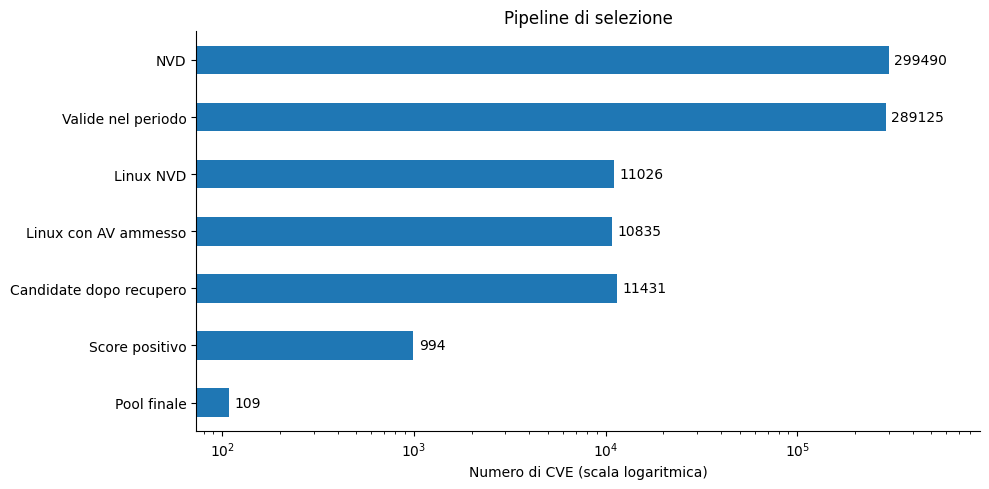

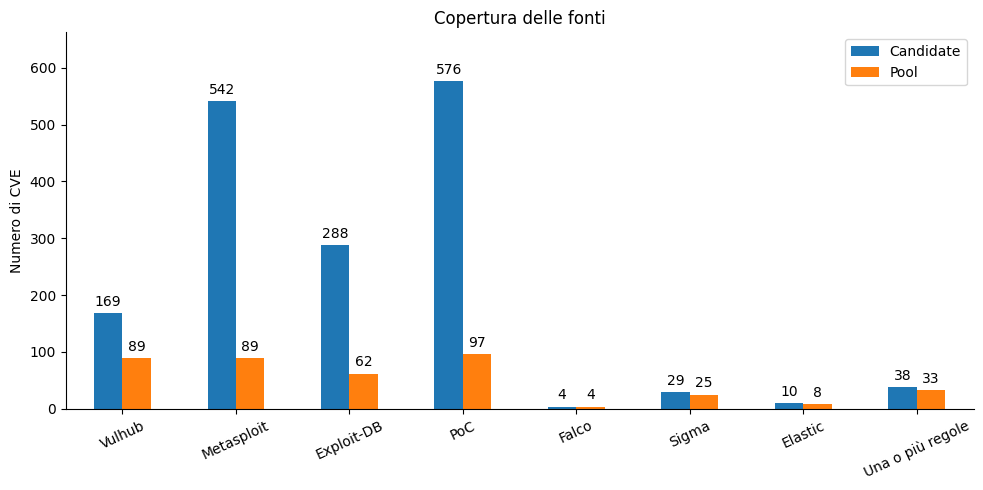

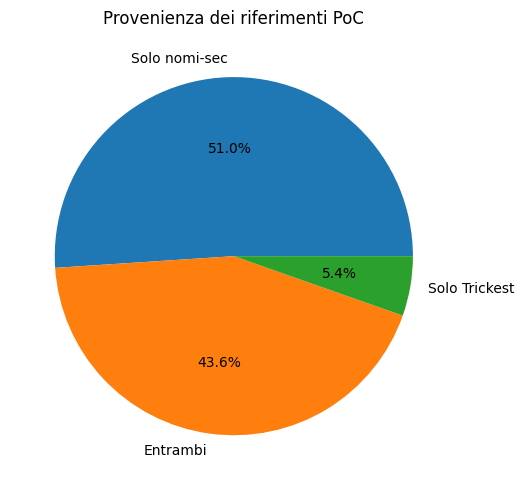

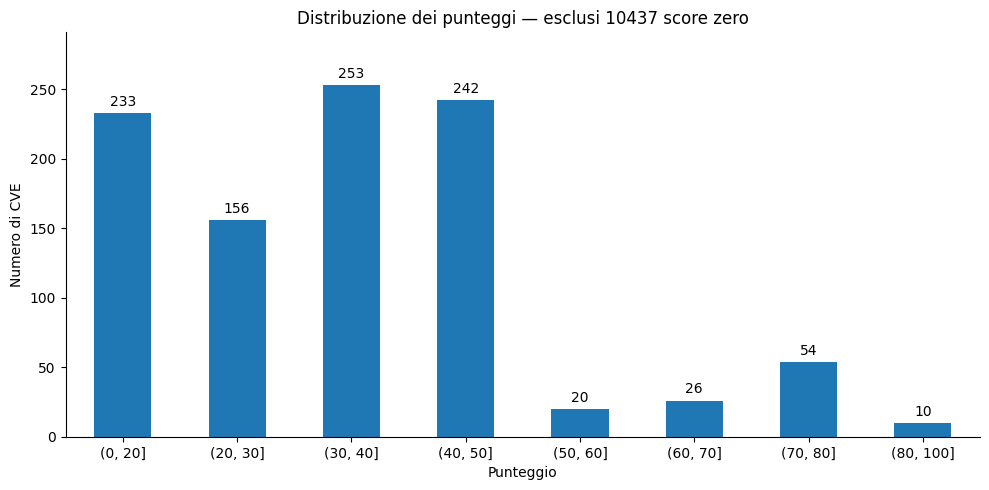

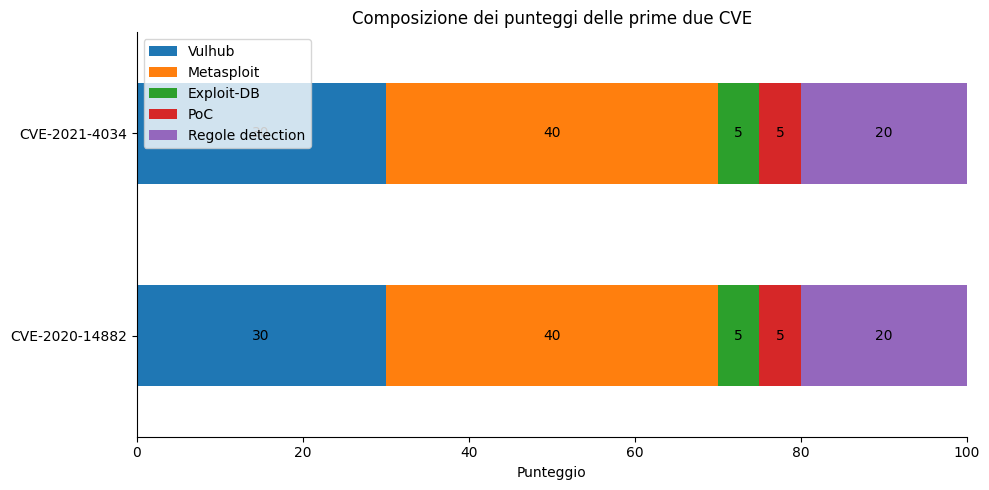

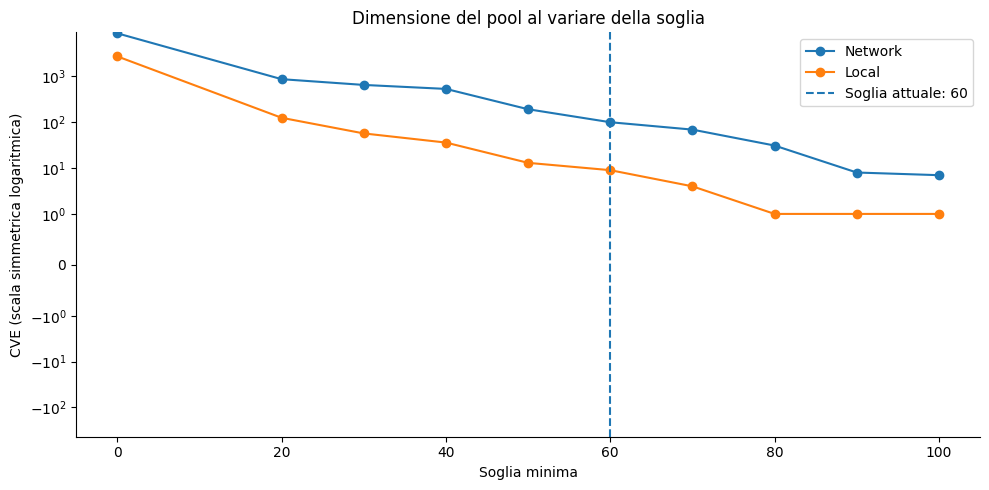

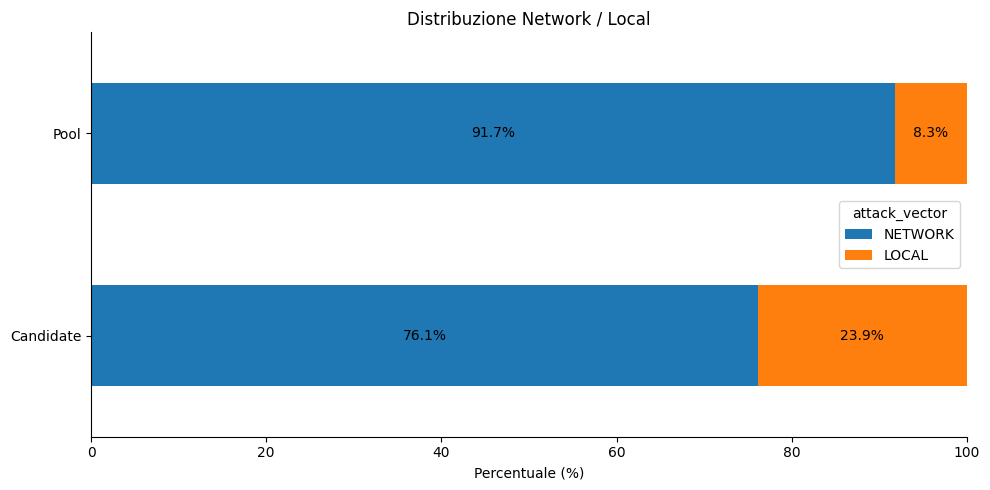

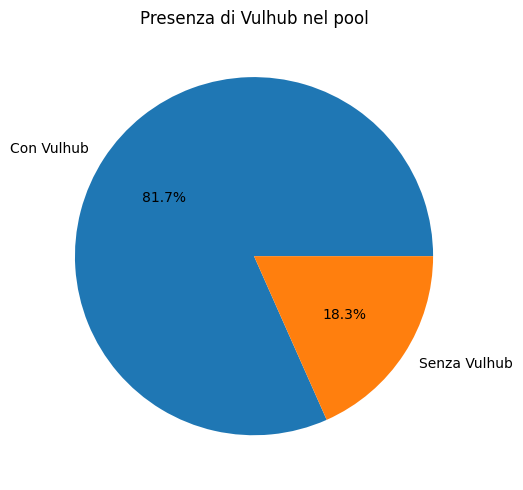

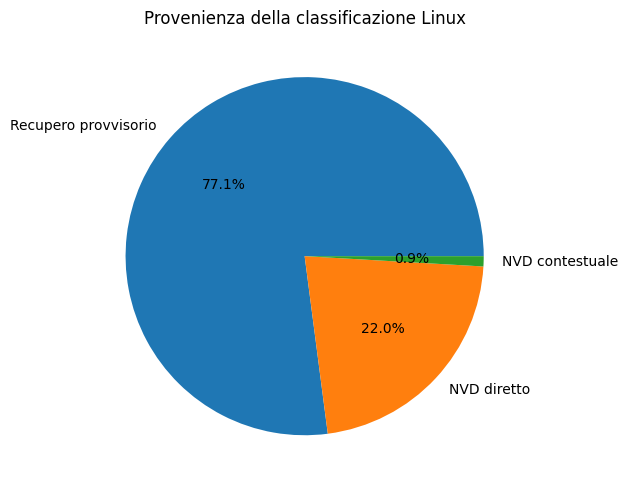

In [13]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Stile dei grafici
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.axisbelow': True})

def finish(title, xlabel='', ylabel='Numero di CVE'):
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

# 1. Conteggi delle fasi di selezione e recupero
stages = {
    'NVD': len(df_all), 'Valide nel periodo': len(df_valid),
    'Linux NVD': len(df_linux_pre_av), 'Linux con AV ammesso': len(df_initial),
    'Candidate dopo recupero': len(df_ranked),
    'Score positivo': df_ranked['score'].gt(0).sum(), 'Pool finale': len(df_pool)
}
ax = pd.Series(stages).plot.barh(logx=True, figsize=(10, 5))
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt='%d', padding=4)
ax.set_xlim(right=max(stages.values()) * 3)
finish('Pipeline di selezione', 'Numero di CVE (scala logaritmica)', '')

# 2. Copertura delle fonti
names = {'has_vulhub': 'Vulhub', 'msf_compatible': 'Metasploit',
         'edb_compatible': 'Exploit-DB', 'has_poc_reference': 'PoC',
         'falco_syscall': 'Falco', 'sigma_eligible': 'Sigma',
         'elastic_eligible': 'Elastic', 'has_detection_rule': 'Una o più regole'}
sources = pd.DataFrame({'Candidate': df_ranked[list(names)].sum(),
                        'Pool': df_pool[list(names)].sum()}).rename(index=names)
ax = sources.plot.bar(rot=25)
for bars in ax.containers:
    ax.bar_label(bars, padding=3)
ax.set_ylim(0, max(1, sources.to_numpy().max()) * 1.15)
finish('Copertura delle fonti')

# 3. Provenienza dei PoC, senza contare due volte le CVE
poc = df_ranked.loc[df_ranked['has_poc_reference'], 'poc_indexes'].astype(str)
a, b = poc.str.contains('nomi-sec', regex=False), poc.str.contains('trickest', regex=False)
poc_counts = pd.Series({'Solo nomi-sec': (a & ~b).sum(),
                        'Entrambi': (a & b).sum(), 'Solo Trickest': (b & ~a).sum(),
                        'Altro / non indicato': (~a & ~b).sum()})

def pie(counts, title):
    counts = counts[counts > 0]
    if counts.empty:
        print(f'{title}: nessun dato')
        return
    counts.plot.pie(autopct='%1.1f%%', ylabel='', figsize=(7, 5))
    plt.title(title)
    plt.tight_layout()
    plt.show()

pie(poc_counts, 'Provenienza dei riferimenti PoC')

# 4. Distribuzione dei punteggi positivi (intervalli del tipo (a, b])
positive = df_ranked.loc[df_ranked['score'] > 0, 'score']
bins = [0, 20, 30, 40, 50, 60, 70, 80, 100]
score_counts = pd.cut(positive, bins=bins).value_counts(sort=False)
ax = score_counts.plot.bar(rot=0)
ax.bar_label(ax.containers[0], padding=3)
ax.set_ylim(0, max(1, score_counts.max()) * 1.15)
finish(f'Distribuzione dei punteggi — esclusi {len(df_ranked)-len(positive)} score zero', 'Punteggio')

# 5. Punteggio delle prime due CVE del ranking
components = {'score_environment': 'Vulhub', 'score_msf': 'Metasploit',
              'score_edb': 'Exploit-DB', 'score_poc': 'PoC', 'score_detection': 'Regole detection'}
if not df_ranked.empty:
    top = df_ranked.head(2).set_index('cve_id')[list(components)].rename(columns=components)
    ax = top.plot.barh(stacked=True)
    ax.invert_yaxis()
    ax.set_xlim(0, MAX_SCORE)
    for bars in ax.containers:
        ax.bar_label(bars, labels=[f'{v:g}' if v > 0 else '' for v in bars.datavalues], label_type='center')
    finish('Composizione dei punteggi delle prime due CVE', 'Punteggio', '')

# 6. Dimensione del pool per soglia e Attack Vector
ax = df_thresholds.set_index('threshold')[['network', 'local']].rename(
    columns={'network': 'Network', 'local': 'Local'}).plot(marker='o')
ax.axvline(MIN_SCORE, linestyle='--', label=f'Soglia attuale: {MIN_SCORE}')
ax.set_yscale('symlog', linthresh=1)
ax.legend()
finish('Dimensione del pool al variare della soglia', 'Soglia minima', 'CVE (scala simmetrica logaritmica)')

# 7. Distribuzione dei vettori di attacco
av = pd.DataFrame({'Candidate': df_ranked['attack_vector'].value_counts(),
                   'Pool': df_pool['attack_vector'].value_counts()}).fillna(0)
av = av.reindex(['NETWORK', 'LOCAL'], fill_value=0).T
percent = av.div(av.sum(axis=1).replace(0, float('nan')), axis=0).fillna(0) * 100
ax = percent.plot.barh(stacked=True)
for bars in ax.containers:
    ax.bar_label(bars, labels=[f'{v:.1f}%' if v > 0 else '' for v in bars.datavalues], label_type='center')
ax.set_xlim(0, 100)
finish('Distribuzione Network / Local', 'Percentuale (%)', '')

# 8. Presenza di Vulhub nel pool
with_vulhub = int(df_pool['has_vulhub'].sum())
pie(pd.Series({'Con Vulhub': with_vulhub, 'Senza Vulhub': len(df_pool)-with_vulhub}),
    'Presenza di Vulhub nel pool')

# 9. Provenienza della classificazione Linux
labels = {'external_provisional': 'Recupero provvisorio', 'linux_direct': 'NVD diretto',
          'linux_context': 'NVD contestuale'}
pie(df_pool['platform_basis'].value_counts().rename(index=labels), 'Provenienza della classificazione Linux')